> **Language & Quick Links**: [🇰🇷 Korean (`notebooks/ko/stage1_asset_and_cq_ko.ipynb`)](../ko/stage1_asset_and_cq_ko.ipynb) · **🇺🇸 English (Current Folder: `notebooks/en/`)** ｜ [Starter README](../../README.md) ｜ [Notebook Index (README)](../README.md) ｜ [Open the Starter demo](https://agentic-ontology-starter-115847445822.asia-northeast3.run.app/)
>
> **Lifecycle Navigation**: [0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb) → **[▶ Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb)** → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → [Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) → [Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb) → [Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)

---

# Stage 1. [Prepare & Analyze] Ready-to-Use Asset Connection, Schema Design, Data Profiling & Golden CQ Definition
## Step 1.1 Structured/Unstructured Asset Scoping & Schema Blueprint · Step 1.2 Data Profiling & 5 Golden CQs / 10 Boundary Cases

Stage 1 executes **Phase 1 (Preparation)** and **Phase 2 (Analysis)** of the methodology. We first define the target **5 Golden Competency Questions (CQs)** and **10 Boundary Cases**, and connect directly to the 10 Ready-to-Use BigQuery tables (`starter_ontology_dw`) via `src/resource_connector.py` (`stage1_resource_check`). The sample CSV files are de-identified synthetic demo data (`provenance=SYNTHETIC_DEMO`).

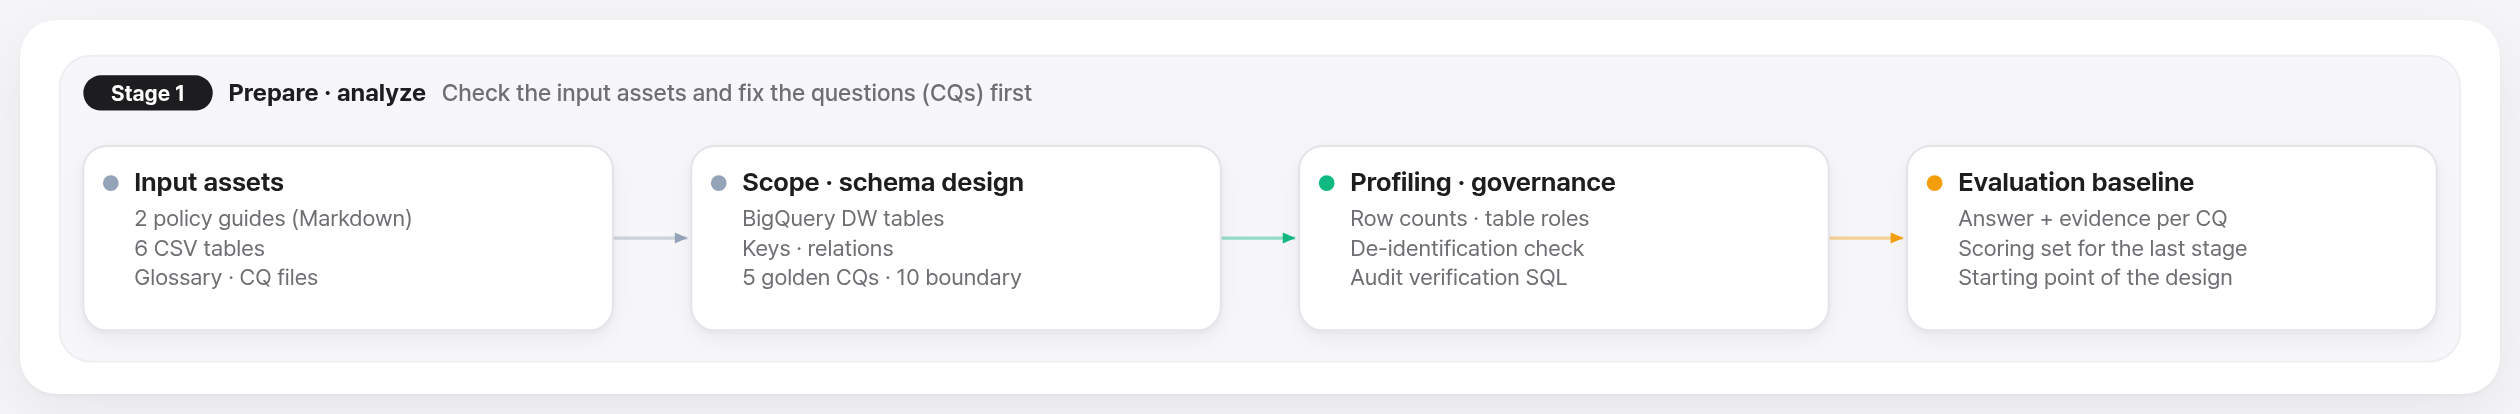


In [ ]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
H.setup("en")
server = DomainMcpServer()


### 1. [Phase 1: Preparation] Raw Input Asset Inventory (`data/input/`) & 10-Table Schema Blueprint (`%%bqsql`)


In [ ]:
H.show(H.raw_inputs_inventory())
H.draw_table_er_blueprint()


In [ ]:
%%bqsql df_schema
SELECT table_name,
       COUNT(*) AS column_count,
       STRING_AGG(CONCAT(column_name, ':', data_type), ', ' ORDER BY ordinal_position) AS columns_spec
FROM `seanjung-poc.starter_ontology_dw.INFORMATION_SCHEMA.COLUMNS`
GROUP BY table_name
ORDER BY table_name


In [ ]:
H.show(df_schema)


### 2. [Phase 2a: Analysis] Stage 1 Resource Verification (`stage1_resource_check`) — Table Profiling & PII De-identification Check


In [ ]:
res_s1 = server.execute_tool("stage1_resource_check", {"steps": ["profile_tables", "scan_guides", "prune_noise", "tag_pii_governance"]})
H.show_tool(res_s1, "table_inventory")
H.show(pd.DataFrame([res_s1["pii_check"]]))


In [ ]:
%%bqsql df_tables
SELECT table_id, row_count, size_bytes,
  CASE WHEN STARTS_WITH(table_id, 'edge_') THEN 'edge'
       WHEN table_id IN ('tb_doc_chunks', 'tb_domain_rules') THEN 'knowledge'
       ELSE 'master' END AS kind
FROM `seanjung-poc.starter_ontology_dw.__TABLES__`
ORDER BY kind, table_id


In [ ]:
H.bar(df_tables, "table_id", "size_bytes", "Table Physical Size in Bytes", horizontal=True)


### 3. [Phase 2b: Structured Ledger Inspection] De-identified Contracts (`CUST_DEMO_*`) Joined with Devices & Plans (`%%bqsql`)


In [ ]:
%%bqsql df_contracts
SELECT c.customer_id, c.contract_id, c.customer_segment, c.age_group, c.welfare_status, c.contract_type,
       c.elapsed_days, c.granted_subsidy_krw, d.device_name, p.plan_name, p.monthly_fee_krw
FROM `seanjung-poc.starter_ontology_dw.tb_customer_contract` c
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d USING (device_id)
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY c.customer_id


In [ ]:
H.show(df_contracts)
H.bar(df_contracts, "customer_id", "elapsed_days",
      "Customer Elapsed Days vs. 180-Day Mandatory Retention Line",
      hline=180, hline_label="180d mandatory")


### 4. [Phase 2c: Subsidy Policy Exploration] Device × Plan Subsidy Structure & Net Price Heatmap (`%%bqsql`)


In [ ]:
%%bqsql df_sub
SELECT s.policy_id, d.device_name, p.plan_name, p.monthly_fee_krw, d.factory_price_krw,
       s.base_subsidy_krw, s.additional_subsidy_cap_krw,
       s.base_subsidy_krw + s.additional_subsidy_cap_krw AS total_subsidy_krw,
       d.factory_price_krw - (s.base_subsidy_krw + s.additional_subsidy_cap_krw) AS net_price_krw,
       s.mandatory_retention_days
FROM `seanjung-poc.starter_ontology_dw.tb_subsidy_policy` s
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d USING (device_id)
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY d.device_name, p.monthly_fee_krw DESC


In [ ]:
d_sub = H.pdf(df_sub)
d_sub["device_plan"] = d_sub["device_name"].str.replace(" 256GB", "") + " / " + d_sub["plan_name"]
H.show(d_sub[["policy_id", "device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "base_subsidy_krw", "additional_subsidy_cap_krw", "total_subsidy_krw", "net_price_krw"]])
H.grouped_bar(d_sub, "device_plan", ["base_subsidy_krw", "additional_subsidy_cap_krw", "net_price_krw"],
              "Base Subsidy, Additional Cap & Net Price by Device × Plan")
H.heatmap(d_sub.pivot(index="device_name", columns="plan_name", values="net_price_krw"),
          "Net Purchase Price Heatmap (KRW)")


### 5. [Phase 2d: Unstructured Chunks, Glossary & Golden CQ Design] Term Frequency (`%%bqsql`) & 5 Golden CQs SQL Ground-Truth Check


In [ ]:
%%bqsql df_terms
SELECT t.term, c.chunk_id, ARRAY_LENGTH(REGEXP_EXTRACT_ALL(c.content, t.pat)) AS hits
FROM `seanjung-poc.starter_ontology_dw.tb_doc_chunks` c,
UNNEST([
  STRUCT("Public Subsidy" AS term, r'(?i)subsidy|subsidies' AS pat),
  STRUCT("15% Retail Cap", r'(?i)15%|additional|total subsidy'),
  STRUCT("180-Day Rule", r'(?i)180-day|180 days|180'),
  STRUCT("Prorated Clawback", r'(?i)formula|prorated|difference'),
  STRUCT("Penalty Settlement", r'(?i)penalty|penalties'),
  STRUCT("25% Selective Discount", r'(?i)selective|25%'),
  STRUCT("Welfare Exemption", r'(?i)welfare|exempt')
]) AS t
ORDER BY t.term, c.chunk_id


In [ ]:
glossary = H.read_json("data/input/05_glossary/business_glossary.json")
H.show(pd.DataFrame([{"term": k, "definition": v} for k, v in glossary.items()] if isinstance(glossary, dict) else glossary))
df_terms_loc = H.pdf(df_terms)
H.heatmap(df_terms_loc.pivot(index="term", columns="chunk_id", values="hits"),
          "Domain Term × Policy Document Chunk Frequency", fmt="{:.0f}")
cqs = H.read_json("data/input/04_cq/golden_competency_questions.json")
H.show(H.check_cq_sql(cqs))
bcs = H.read_json("data/input/04_cq/boundary_cases.json")
H.show(bcs, ["case_id", "root_cause_code", "missing_context", "query", "expected_behavior"])


### 6. [Phase 2e: 5-Axis Graph Engine Selection Checklist] BigQuery Property Graph (Default) vs. Cloud Spanner Graph (100 PU) vs. Graph Fabric (`both`)


In [ ]:
H.show(H.engine_selection_checklist_df())


### Q&A
- **Q.** Why do we define Golden CQs, `verification_sql`, and the 5-Axis Graph Engine Selection Checklist before building the ontology and graph?
  - **A.** Defining target CQs, deterministic ground-truth SQL (`expected_math`, `verification_sql`, `grounded_chunk`), and the 5-Axis Graph Engine Selection Checklist (`bigquery` default | `spanner` | `both`) in Stage 1 scopes only the necessary tables/infrastructure and provides an automated grading oracle in Stage 3 and Stage 5.

### Data Analysis Key Findings
- All 10 tables (62 rows) in `starter_ontology_dw` are populated and verified via `INFORMATION_SCHEMA.COLUMNS`, with `0` de-identification violations across `CUST_DEMO_001~006`.
- 5 of the 6 customer contracts (`elapsed_days`: 45–120 days) are within the 180-day mandatory retention window, requiring prorated penalty or welfare exemption evaluation upon plan downgrade.
- Executing `verification_sql` for all 5 Golden CQs (`CQ-01`–`CQ-05`) on live BigQuery matched `expected_math` in all 5 cases (`match=True`), and the 5-Axis Graph Engine Selection Checklist (`input_manifest.json`) verified the selection criteria for `bigquery` (default), `spanner`, and `both` (Graph Fabric).

### Insights or Next Steps
- Proceed to `Stage 2 (Parse & Integrate)` to see how unstructured policy guides are parsed into SHA-256 anchored chunks and integrated into the 3-Layer LLM-Wiki and Semantic Ontology Graph.

---
> **Next Navigation**: [⬅️ 0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb) ｜ [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [➡️ Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) ｜ [🌐 Korean Version](../ko/stage1_asset_and_cq_ko.ipynb) ｜ [📖 Methodology Doc](../../methodology/en/01_stage1_asset_and_cq_en.md)
